# Module B: Cancellation Risk (Classification), Part 1

**Goal:** predict `is_canceled` and compare classifiers fairly on one shared split. All scores are 5-fold stratified CV on the training set; the test set stays untouched until Day 4. Models are compared mainly on ROC-AUC (threshold-independent); the decision threshold is tuned separately on Day 4.

| Section | Content |
|---|---|
| 0 | Setup, shared split, helper functions, majority baseline |
| 1 | Logistic Regression, coefficients and the leakage check |
| 2 | Naive Bayes |
| 3 | K-Nearest Neighbours (k tuned with CV) |
| 4 | Support Vector Machine |
| 5 | Decision Tree |
| 6 | Random Forest |
| 7 | Learning curve |
| 8 | Final leaderboard (saved to CSV) |
| 9 | Summary and decision log |

## 0. Setup

In [26]:
# Imports: all libraries in one place (moved here from the cells below; duplicates removed)
import sys
sys.path.insert(0, "..")          # project root, so `src` can be found

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (StratifiedKFold, cross_validate, cross_val_predict,
                                     train_test_split, GridSearchCV, learning_curve)
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from src._01_code.features import build_preprocessor

In [27]:
# Global settings: fixed seed and 80/20 split so every model sees identical data; load the cleaned dataset
RANDOM_STATE = 42
TEST_SIZE = 0.2
TARGETS = ["is_canceled", "adr"]

df = pd.read_csv("../data/clean/hotel_clean.csv")

In [28]:
# Stratified 80/20 train/test split: keeps the 27.5% cancel rate in both sets; the test set stays untouched until the final evaluation (Day 4)

train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["is_canceled"], random_state=RANDOM_STATE
)


# Features exclude BOTH targets: adr is the target for Module A, is_canceled for Module B
X_train = train_df.drop(columns=TARGETS)
X_test = test_df.drop(columns=TARGETS)
y_train, y_test = train_df["is_canceled"], test_df["is_canceled"]

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

In [29]:
# Helpers: make_pipe (preprocessing + model), cv_score (5-fold CV metrics = one leaderboard row), plot_cm (CV confusion matrix)

def make_pipe(model, num=None, cat=None):
    num = num_cols if num is None else num
    cat = cat_cols if cat is None else cat
    return Pipeline([
        ("prep", build_preprocessor(num, cat)),
        ("model", model),
    ])

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

def cv_score(name, pipe, X=None, y=None):
    X = X_train if X is None else X
    y = y_train if y is None else y
    cv = cross_validate(pipe, X, y, cv=CV, scoring=SCORING,
                        n_jobs=-1, return_train_score=True)
    row = {"model": name}
    for m in SCORING:
        row[m] = cv[f"test_{m}"].mean()
    row["train_f1"] = cv["train_f1"].mean() # compare with test F1 to spot overfitting
    return row

def plot_cm(name, pipe, X=None, y=None):
    X = X_train if X is None else X
    y = y_train if y is None else y
    y_pred = cross_val_predict(pipe, X, y, cv=CV, n_jobs=-1)
    ConfusionMatrixDisplay.from_predictions(
        y, y_pred, display_labels=["stays", "cancels"],
        normalize="true",             # each row is a share of the true class (bottom-left = missed cancellations)
    )
    plt.title(name)
    plt.show()

In [30]:
# Majority-class baseline: always predicts 'stays'; every model must beat it on F1 and ROC-AUC (the precision warning is expected, it never predicts 'cancels')
results = [cv_score("Majority baseline", make_pipe(DummyClassifier(strategy="most_frequent")))]
pd.DataFrame(results)

/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/hirunadilmith/Learning/Macine Learning/Hotel Booking Intelligence project/01-code/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.0,0.0,0.0,0.5,0.0


## 1. Logistic Regression

### 1.1 Fit on all features (reference row)

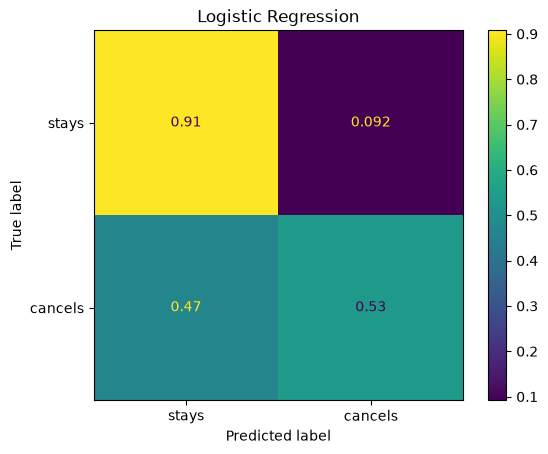

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"LogReg (leaky, reference only)",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351


In [31]:
# Logistic Regression on ALL features (still includes the leaky columns, so this row is for reference only); max_iter=1000 so it converges
logreg = make_pipe(LogisticRegression(max_iter=1000))
results.append(cv_score("LogReg (leaky, reference only)", logreg))
plot_cm("Logistic Regression", logreg)
pd.DataFrame(results)

### 1.2 What the model learned: coefficients

In [32]:
# Coefficients of the leaky model: positive weight pushes toward 'cancels', negative toward 'stays'

logreg.fit(X_train, y_train)
feat_names = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=feat_names)
coefs.sort_values().iloc[list(range(8)) + list(range(-8, 0))]   # 8 most negative, 8 most positive

num__required_car_parking_spaces   -3.168648
cat__reserved_room_type_A          -1.811797
cat__agent_152                     -1.646883
cat__deposit_type_No Deposit       -1.592048
cat__assigned_room_type_G          -1.515462
cat__assigned_room_type_I          -1.438531
cat__country_JPN                   -1.272972
cat__agent_243                     -1.039776
cat__agent_242                      1.362049
cat__country_AGO                    1.497022
cat__deposit_type_Non Refund        1.564639
cat__reserved_room_type_G           1.608049
cat__country_PRT                    1.612119
cat__assigned_room_type_A           1.796161
cat__agent_9                        1.913494
cat__agent_240                      2.105316
dtype: float64

In [33]:
# Look up the weights of three features guessed from the EDA: previous cancellations, lead time, special requests
coefs[["num__previous_cancellations", "num__lead_time", "num__total_of_special_requests"]]

num__previous_cancellations       0.511884
num__lead_time                    0.479763
num__total_of_special_requests   -0.643556
dtype: float64

### 1.3 Leakage check: drop columns unknown at booking time

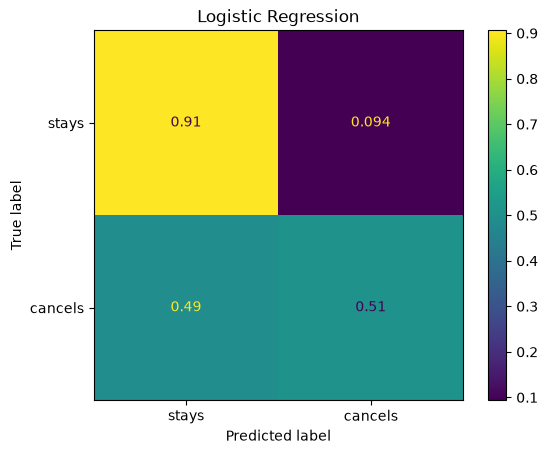

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"LogReg (leaky, reference only)",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351
2,LogReg (safe),0.796298,0.671206,0.506928,0.577562,0.854766,0.579212


In [34]:
# Leakage check: drop assigned_room_type and booking_changes (neither is known at booking time) and re-score; ROC-AUC fell 0.863 -> 0.855, and 0.855 is the honest number

LEAKY = ["assigned_room_type", "booking_changes"]
X_train_safe = X_train.drop(columns=LEAKY)

num_safe = [c for c in num_cols if c not in LEAKY]
cat_safe = [c for c in cat_cols if c not in LEAKY]

logreg_safe = make_pipe(LogisticRegression(max_iter=1000), num=num_safe, cat=cat_safe)
results.append(cv_score("LogReg (safe)", logreg_safe, X=X_train_safe))
plot_cm("Logistic Regression", logreg_safe)
pd.DataFrame(results)

In [35]:
# Coefficients of the SAFE model (fixed: the old cell read the leaky `logreg`, so it just repeated the earlier table)
logreg_safe.fit(X_train_safe, y_train)
feat_names = logreg_safe.named_steps["prep"].get_feature_names_out()
coefs_safe = pd.Series(logreg_safe.named_steps["model"].coef_[0], index=feat_names)
coefs_safe.sort_values().iloc[list(range(8)) + list(range(-8, 0))]   # 8 most negative, 8 most positive

num__required_car_parking_spaces   -3.171154
cat__agent_152                     -1.619210
cat__deposit_type_No Deposit       -1.618345
cat__country_JPN                   -1.228947
cat__agent_28                      -1.123567
cat__agent_243                     -0.970508
cat__agent_16                      -0.932764
cat__agent_40                      -0.783303
cat__country_MAR                    0.987028
cat__agent_134                      1.205982
cat__agent_242                      1.432336
cat__country_AGO                    1.445038
cat__country_PRT                    1.609044
cat__deposit_type_Non Refund        1.634508
cat__agent_9                        1.900936
cat__agent_240                      2.096697
dtype: float64

In [36]:
# Make the safe feature set the default for all later models (train AND test must both drop the leaky columns)

X_train, X_test = X_train.drop(columns=LEAKY), X_test.drop(columns=LEAKY)
num_cols, cat_cols = num_safe, cat_safe

### Insight: Logistic Regression

- **Beats the baseline clearly on ranking.** ROC-AUC 0.855 vs 0.50 and F1 0.58 vs 0.
  Accuracy (0.80 vs 0.73) understates the gap because 72.5% of bookings don't cancel.
- **Good ranking, wrong default threshold.** At 0.5 it catches only about half of the
  cancellations (recall 0.51), but the high ROC-AUC means risky bookings are already
  scored above safe ones. Lowering the threshold (Day 4) should raise recall a lot.
- **Underfitting, not overfitting.** Train F1 (0.58) ≈ validation F1 (0.58). A linear model
  can't capture non-linear effects (e.g. lead time, or feature combinations like hotel type × deposit),
  so I expect tree-based models to do better.
- **What drives cancellations.** Fewer cancellations: parking requests, special requests
  (signs of a committed guest). More cancellations: longer lead time, previous cancellations
  (strong but rare, 1.9% of guests), non-refundable deposits (a known dataset quirk:
  agent group blocks cancelled in bulk).
- **Leakage found and removed.** `assigned_room_type` and `booking_changes` are only known
  after booking. Dropping them lowered ROC-AUC from 0.863 to 0.855; 0.855 is the honest score.

## 2. Naive Bayes

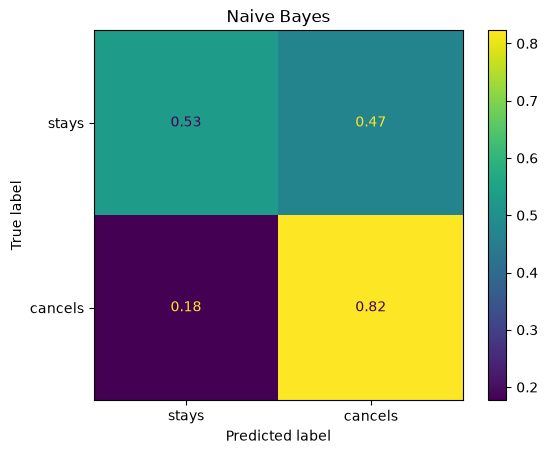

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"LogReg (leaky, reference only)",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351
2,LogReg (safe),0.796298,0.671206,0.506928,0.577562,0.854766,0.579212
3,Naive Bayes,0.610890,0.399852,0.822662,0.537681,0.748963,0.539874


In [37]:
# Gaussian Naive Bayes: assumes bell-shaped, independent features, which fits one-hot columns badly
nb = make_pipe(GaussianNB())
results.append(cv_score("Naive Bayes", nb))
plot_cm("Naive Bayes", nb)
pd.DataFrame(results)

### Insight: Naive Bayes

**Result:** ROC-AUC 0.749 (LogReg: 0.855), accuracy 0.611, which is **below the
0.725 majority baseline**. Recall is high (0.82) but precision is low (0.40):
it catches most cancellations, but 6 in 10 of its "cancels" flags are false alarms.

**Why it failed:** GaussianNB assumes each feature is (1) bell-shaped and
(2) independent of the others, given the class. Both assumptions break here:
- Most of our 171 features are one-hot 0/1 columns, which are not bell-shaped.
  For rare categories (e.g. a small country), the fitted bell curve is a thin
  spike, so a single rare value can overrule every other feature.
- Related columns (market segment, distribution channel, agent) carry the
  same signal, and NB counts it several times.
Together these push probabilities to extremes, which hurts the ranking.

**Not overfitting:** train F1 (0.540) ≈ CV F1 (0.538). The problem is high
bias from wrong assumptions, so more data won't fix it.

**Business takeaway:** high recall at the default threshold is not a win.
Logistic Regression ranks bookings better, so lowering its threshold would
reach the same recall with fewer false alarms, meaning fewer loyal guests
annoyed by deposit requests.

**Decision:** drop Naive Bayes from the shortlist. Keep it on the leaderboard as
an example of how a model's assumptions can fail on this kind of data.

## 3. K-Nearest Neighbours (KNN)

### 3.1 First run: k=15 on a 20k sample

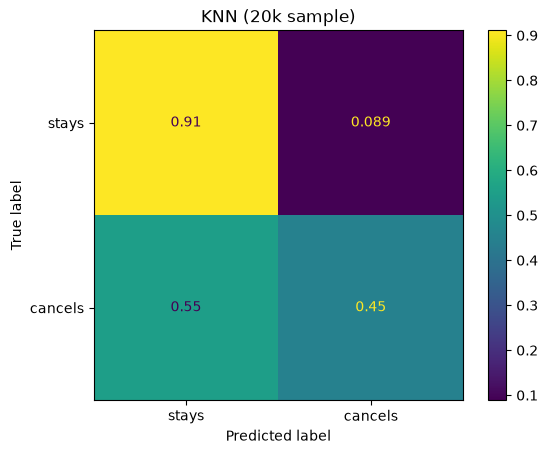

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"LogReg (leaky, reference only)",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351
2,LogReg (safe),0.796298,0.671206,0.506928,0.577562,0.854766,0.579212
3,Naive Bayes,0.610890,0.399852,0.822662,0.537681,0.748963,0.539874
4,KNN (20k sample),0.784600,0.657580,0.451220,0.535021,0.807314,0.604264


In [38]:
# First KNN run: k=15 on a stratified 20k sample (KNN is slow, and its distances rely on the scaled pipeline features)
X_s, _, y_s, _ = train_test_split(
    X_train, y_train, train_size=20_000,
    stratify=y_train, random_state=RANDOM_STATE)

knn = make_pipe(KNeighborsClassifier(n_neighbors=15))
results.append(cv_score("KNN (20k sample)", knn, X=X_s, y=y_s))
plot_cm("KNN (20k sample)", knn, X=X_s, y=y_s)
pd.DataFrame(results)

### 3.2 Tune k with cross-validation on the full training set

In [ ]:
# Choose k by 5-fold CV on the full training set, scored by ROC-AUC (threshold-independent), over a grid of k values
knn_grid = GridSearchCV(
    make_pipe(KNeighborsClassifier()),
    param_grid={"model__n_neighbors": [5, 15, 31, 51, 101, 201]},
    scoring="roc_auc",            # ROC-AUC picks k by ranking quality, not by the 0.5 threshold
    cv=CV, n_jobs=-1, return_train_score=True,
)
knn_grid.fit(X_train, y_train)

print(knn_grid.best_params_, knn_grid.best_score_)
pd.DataFrame(knn_grid.cv_results_)[
    ["param_model__n_neighbors", "mean_train_score", "mean_test_score"]]

### 3.3 Add the tuned model to the leaderboard

In [ ]:
# Add the tuned KNN (full training data) to the leaderboard
best_k = knn_grid.best_params_["model__n_neighbors"]   # best k from the ROC-AUC grid search above
knn_best = make_pipe(KNeighborsClassifier(n_neighbors=best_k))
results.append(cv_score("KNN (tuned, full data)", knn_best))
pd.DataFrame(results)

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"Logistic Regression (Leaky, for reference))",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351
2,LogReg (no leaky cols),0.796298,0.671206,0.506928,0.577562,0.854766,0.579212
3,Naive Bayes,0.610890,0.399852,0.822662,0.537681,0.748963,0.539874
4,KNN (20k sample),0.784600,0.657580,0.451220,0.535021,0.807314,0.604264
5,"KNN (tuned, full data)",0.797441,0.695894,0.466572,0.558586,0.835403,0.583514


### Insight: KNN

**KNN, tuned with 5-fold CV on the full training set:**

| k | Train ROC-AUC | CV ROC-AUC | Gap |
|---|---|---|---|
| 5 | 0.918 | 0.807 | 0.111 |
| 15 | 0.880 | 0.832 | 0.048 |
| 31 | 0.862 | 0.835 | 0.027 |
| **51** | 0.853 | **0.835** | 0.018 |
| 101 | 0.841 | 0.831 | 0.010 |
| 201 | 0.830 | 0.824 | 0.006 |

**Choosing k:** small k overfits (k=5 memorizes the training data, with a gap of 0.11). Large k underfits (k=201 loses ranking quality). CV ROC-AUC peaks at k=31 to 51, so I chose **k=51**. I chose by ROC-AUC rather than F1 because F1 depends on the 0.5 threshold, which I will tune separately on Day 4. F1 favoured k=5, the most overfit option.

**More data helped:** using all 69k rows instead of a 20k sample raised ROC-AUC from 0.807 to 0.835, and the confusion matrix showed precision going up from 0.66 to 0.70.

**Still behind Logistic Regression** (0.835 vs 0.855 ROC-AUC). KNN counts all 171 features equally in its distance, so noisy one-hot columns (agents, countries) blur what "similar booking" means. At 0.5 it still misses over half of the real cancellations (recall 0.47). It is also slow at prediction time, because each new booking is compared with every training booking, which makes it a poor choice for the Streamlit app.

**Takeaway:** a straight-line model with learned feature weights beats a "similar bookings" model on this data.

## 4. Support Vector Machine (SVM)

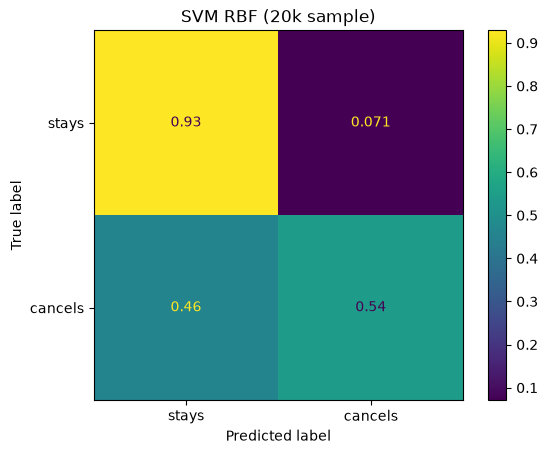

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"Logistic Regression (Leaky, for reference))",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351
2,LogReg (no leaky cols),0.796298,0.671206,0.506928,0.577562,0.854766,0.579212
3,Naive Bayes,0.610890,0.399852,0.822662,0.537681,0.748963,0.539874
4,KNN (20k sample),0.784600,0.657580,0.451220,0.535021,0.807314,0.604264
5,"KNN (tuned, full data)",0.797441,0.695894,0.466572,0.558586,0.835403,0.583514
6,SVM RBF (20k sample),0.822050,0.741962,0.540227,0.625179,0.868354,0.662929


In [ ]:
# SVM with an RBF kernel on the 20k sample (training time grows roughly with n^2, so the full data is too slow)
svm = make_pipe(SVC(kernel="rbf", C=1.0, gamma="scale"))
results.append(cv_score("SVM RBF (20k sample)", svm, X=X_s, y=y_s))
plot_cm("SVM RBF (20k sample)", svm, X=X_s, y=y_s)
pd.DataFrame(results)

### Insight: SVM

SVM (RBF kernel, 20k sample): ROC-AUC 0.868, the best so far, above Logistic Regression (0.855) even though it saw only 20k rows. The curved boundary captures non-linear interactions that a linear model misses. It has the highest precision (0.74) but still misses 46% of cancellations at the 0.5 threshold. Train F1 0.66 vs CV 0.63 shows mild overfitting with untuned C and gamma. Training time grows roughly with n², so it can't use the full data, and it is slow to predict, so it is unlikely to be the deployed model.

## 5. Decision Tree

In [ ]:
# Decision Tree at several depths: shallow = underfit, unlimited = overfit (compare train vs CV F1)
for d in [3, 6, 9, 12,  None]:
    tree = make_pipe(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))
    results.append(cv_score(f"Tree depth={d}", tree))
pd.DataFrame(results)

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"Logistic Regression (Leaky, for reference))",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351
2,LogReg (no leaky cols),0.796298,0.671206,0.506928,0.577562,0.854766,0.579212
3,Naive Bayes,0.610890,0.399852,0.822662,0.537681,0.748963,0.539874
4,KNN (20k sample),0.784600,0.657580,0.451220,0.535021,0.807314,0.604264
5,"KNN (tuned, full data)",0.797441,0.695894,0.466572,0.558586,0.835403,0.583514
6,SVM RBF (20k sample),0.822050,0.741962,0.540227,0.625179,0.868354,0.662929
7,Tree depth=3,0.763735,0.613272,0.378906,0.468300,0.779533,0.468621
8,Tree depth=6,0.798888,0.671351,0.527002,0.589865,0.847857,0.592099
9,Tree depth=None,0.797716,0.631986,0.631684,0.631787,0.747244,0.993841


### Insight: Decision Tree

**Decision Tree, effect of `max_depth` (5-fold CV on the full training set):**

| max_depth | Train F1 | CV F1 | Gap | CV ROC-AUC |
|---|---|---|---|---|
| 3 | 0.469 | 0.468 | 0.00 | 0.780 |
| 6 | 0.592 | 0.590 | 0.00 | 0.848 |
| 9 | 0.643 | 0.633 | 0.01 | 0.876 |
| **12** | 0.712 | 0.671 | 0.04 | **0.881** |
| None | 0.994 | 0.632 | 0.36 | 0.747 |

**Underfit to overfit:** depth 3 is too shallow (train ≈ CV, both low). Deeper trees capture more of the non-linear structure, so ROC-AUC climbs from 0.78 to 0.88 up to depth 12. With no limit the tree memorizes the training data (train F1 0.99, gap 0.36), and its ROC-AUC collapses to 0.75 because the hard 0/1 leaf predictions give a poor ranking.

**Best single tree: depth 12 (ROC-AUC 0.881, F1 0.671)**, which beats Logistic Regression (0.855), SVM (0.868) and KNN (0.835). The gain over linear models fits the idea that lead time, deposit type and market segment interact in non-linear ways, which a tree can capture and a straight-line model cannot. The gap between train and CV F1 is starting to open at depth 12 (0.04), so the peak is probably between 12 and unlimited depth.

**Limitations:** a single tree is unstable, since small changes in the data can change its splits. It also loses ROC-AUC quickly once depth is unrestricted, so the depth must be tuned with CV.

## 6. Random Forest

### 6.1 Unlimited depth

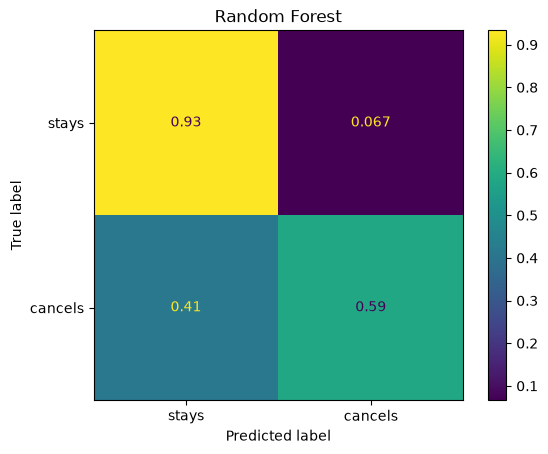

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"Logistic Regression (Leaky, for reference))",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351
2,LogReg (no leaky cols),0.796298,0.671206,0.506928,0.577562,0.854766,0.579212
3,Naive Bayes,0.610890,0.399852,0.822662,0.537681,0.748963,0.539874
4,KNN (20k sample),0.784600,0.657580,0.451220,0.535021,0.807314,0.604264
5,"KNN (tuned, full data)",0.797441,0.695894,0.466572,0.558586,0.835403,0.583514
6,SVM RBF (20k sample),0.822050,0.741962,0.540227,0.625179,0.868354,0.662929
7,Tree depth=3,0.763735,0.613272,0.378906,0.468300,0.779533,0.468621
8,Tree depth=6,0.798888,0.671351,0.527002,0.589865,0.847857,0.592099
9,Tree depth=None,0.797716,0.631986,0.631684,0.631787,0.747244,0.993841


In [ ]:
# Random Forest: 200 deep trees, min_samples_leaf=5 stops leaves from memorizing single bookings
rf = make_pipe(RandomForestClassifier(
    n_estimators=200, max_depth=None, min_samples_leaf=5,
    n_jobs=-1, random_state=RANDOM_STATE))
results.append(cv_score("Random Forest (depth None, leaf 5)", rf))
plot_cm("Random Forest (depth None, leaf 5)", rf)
pd.DataFrame(results)

### 6.2 Limited to depth 12

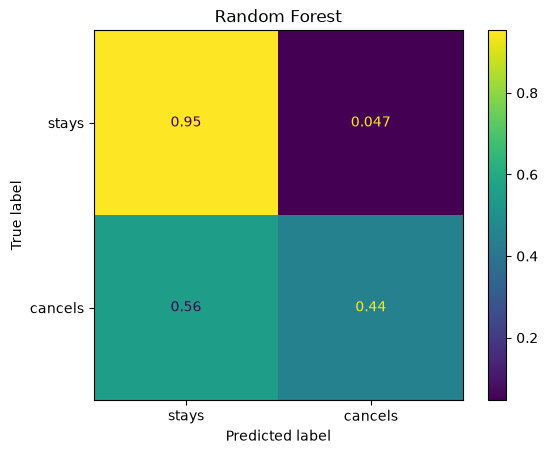

,model,accuracy,precision,recall,f1,roc_auc,train_f1
0,Majority baseline,0.725295,0.000000,0.000000,0.000000,0.500000,0.000000
1,"Logistic Regression (Leaky, for reference))",0.804591,0.685959,0.532691,0.599623,0.863432,0.601351
2,LogReg (no leaky cols),0.796298,0.671206,0.506928,0.577562,0.854766,0.579212
3,Naive Bayes,0.610890,0.399852,0.822662,0.537681,0.748963,0.539874
4,KNN (20k sample),0.784600,0.657580,0.451220,0.535021,0.807314,0.604264
5,"KNN (tuned, full data)",0.797441,0.695894,0.466572,0.558586,0.835403,0.583514
6,SVM RBF (20k sample),0.822050,0.741962,0.540227,0.625179,0.868354,0.662929
7,Tree depth=3,0.763735,0.613272,0.378906,0.468300,0.779533,0.468621
8,Tree depth=6,0.798888,0.671351,0.527002,0.589865,0.847857,0.592099
9,Tree depth=None,0.797716,0.631986,0.631684,0.631787,0.747244,0.993841


In [ ]:
# Random Forest limited to depth 12, to show that shallow trees underfit even when averaged
rf_d12 = make_pipe(RandomForestClassifier(
    n_estimators=200, max_depth=12, min_samples_leaf=5,
    n_jobs=-1, random_state=RANDOM_STATE))
results.append(cv_score("Random Forest (depth 12, leaf 5)", rf_d12))
plot_cm("Random Forest", rf_d12)
pd.DataFrame(results)

### Insight: Random Forest

Random Forest (200 trees, min_samples_leaf=5): the best model so far, with ROC-AUC 0.905 (vs 0.881 for the best single tree), accuracy 0.838 and precision 0.77. Each tree sees a random sample of bookings and a random subset of features, so the trees make different mistakes, and averaging their votes cancels the noise (variance reduction) while keeping the low bias of deep trees. Limiting the forest to depth 12 made it worse (ROC-AUC 0.886, recall 0.44): averaging reduces variance but cannot fix the underfitting of shallow trees. At the 0.5 threshold it still misses about 41% of real cancellations, which the threshold tuning on Day 4 will address.

## 7. Learning curve

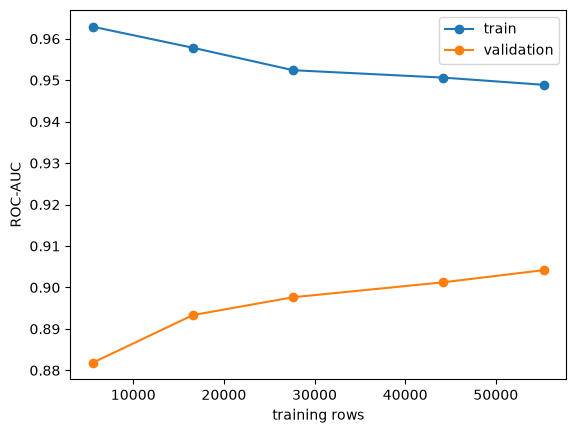

In [ ]:
# Learning curve for the forest: train vs validation ROC-AUC as the training set grows (100 trees to keep it quick)
rf_lc = make_pipe(RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                                          n_jobs=-1, random_state=RANDOM_STATE))
sizes, tr, va = learning_curve(
    rf_lc, X_train, y_train, cv=CV, scoring="roc_auc",
    train_sizes=[0.1, 0.3, 0.5, 0.8, 1.0], n_jobs=1)   # n_jobs=1: the forest already uses all cores

plt.plot(sizes, tr.mean(axis=1), "o-", label="train")
plt.plot(sizes, va.mean(axis=1), "o-", label="validation")
plt.xlabel("training rows"); plt.ylabel("ROC-AUC"); plt.legend(); plt.show()

### Insight: Learning curve

Learning curve, Random Forest (100 trees): validation ROC-AUC rises from 0.882 (5.5k rows) to 0.904 (55k rows) but with diminishing returns (+0.003 per step at the end), so more data would help only a little. Train ROC-AUC (0.95) stays above validation (0.90), a gap of about 0.045 that shrinks as data grows: moderate overfitting (high variance), not underfitting. Improvements are more likely to come from regularization (min_samples_leaf, max_features) or a different model such as gradient boosting than from more rows.

## 8. Final leaderboard

In [ ]:
# Build the final leaderboard: drop duplicate rows from re-runs, add the train/CV F1 gap, sort by ROC-AUC, save for Day 4
leaderboard = (pd.DataFrame(results)
                 .drop_duplicates(subset="model", keep="last")
                 .assign(gap_f1=lambda d: d["train_f1"] - d["f1"])
                 .sort_values("roc_auc", ascending=False)
                 .reset_index(drop=True))

Path("../reports").mkdir(exist_ok=True)
leaderboard.to_csv("../reports/day3_leaderboard.csv", index=False)
leaderboard.round(3)

,model,accuracy,precision,recall,f1,roc_auc,train_f1,gap_f1
0,"Random Forest (depth None, leaf 5)",0.838,0.770,0.588,0.666,0.905,0.739,0.072
1,"Random Forest (depth 12, leaf 5)",0.813,0.781,0.444,0.566,0.886,0.581,0.015
2,Tree depth=12,0.826,0.699,0.645,0.671,0.881,0.712,0.041
3,Tree depth=9,0.816,0.703,0.577,0.633,0.876,0.643,0.010
4,SVM RBF (20k sample),0.822,0.742,0.540,0.625,0.868,0.663,0.038
5,"LogReg (leaky, reference only)",0.805,0.686,0.533,0.600,0.863,0.601,0.002
6,LogReg (safe),0.796,0.671,0.507,0.578,0.855,0.579,0.002
7,Tree depth=6,0.799,0.671,0.527,0.590,0.848,0.592,0.002
8,"KNN (tuned, full data)",0.797,0.696,0.467,0.559,0.835,0.584,0.025
9,KNN (20k sample),0.785,0.658,0.451,0.535,0.807,0.604,0.069


## 9. Summary: models and decisions


**Leaderboard** (5-fold CV on the training set, threshold 0.5, sorted by ROC-AUC):

| Model | ROC-AUC | F1 | Precision | Recall | Train/CV F1 gap |
|---|---|---|---|---|---|
| **Random Forest (depth None, leaf 5)** | **0.905** | 0.666 | 0.770 | 0.588 | 0.072 |
| Random Forest (depth 12, leaf 5) | 0.886 | 0.566 | 0.781 | 0.444 | 0.015 |
| Decision Tree (depth 12) | 0.881 | 0.671 | 0.699 | 0.645 | 0.041 |
| Decision Tree (depth 9) | 0.876 | 0.633 | 0.703 | 0.577 | 0.010 |
| SVM RBF (20k sample) | 0.868 | 0.625 | 0.742 | 0.540 | 0.038 |
| LogReg (safe) | 0.855 | 0.578 | 0.671 | 0.507 | 0.002 |
| KNN (k=51, full data) | 0.835 | 0.559 | 0.696 | 0.467 | 0.025 |
| Naive Bayes | 0.749 | 0.538 | 0.400 | 0.823 | 0.002 |
| Majority baseline | 0.500 | 0.000 | 0.000 | 0.000 | 0.000 |

**Key findings**
- **Tree-based models win** (0.88 to 0.905 ROC-AUC) over linear (0.855), distance-based (0.835) and probabilistic (0.749) models. Effects such as lead time, deposit type and market segment are non-linear and interact, and trees learn that automatically.
- **A forest beats a single tree** (0.905 vs 0.881) because averaging many different deep trees cancels their noise (lower variance) while keeping their low bias. A depth-limited forest is worse (0.886), since averaging cannot fix the underfitting of shallow trees.
- **Bias–variance in practice:** Naive Bayes and depth-3 trees underfit (train ≈ CV, both low). Unlimited trees and k=5 KNN overfit (train F1 0.99 vs CV 0.63 for the tree). The learning curve for the forest shows validation ROC-AUC still rising slowly (0.882 → 0.904) and a gap of about 0.045, i.e. moderate overfitting where more data gives only small gains.
- **F1 at the 0.5 threshold is misleading.** It favoured the most overfit settings (KNN k=5, unlimited tree) and made Naive Bayes look reasonable (recall 0.82) despite the worst ranking. Apart from Naive Bayes, every model still misses over a third of real cancellations at 0.5 (35% to 62%).

**Decision log**
1. **Dropped `assigned_room_type` and `booking_changes`.** Neither is known when a booking is made: guests who stay get reassigned rooms and accumulate changes, while cancelled bookings do not. Removing them lowered LogReg ROC-AUC from 0.863 to 0.855. I kept the lower, honest number, and I would drop them even if the score had not moved.
2. **Models are compared on CV ROC-AUC**, because it measures ranking and does not depend on the 0.5 threshold, which I will tune separately on Day 4 from business costs.
3. **KNN: k=51 on the full training set**, chosen by 5-fold CV ROC-AUC (k=31 and 51 tied at 0.835). F1 picked k=5, the most overfit option, so I rejected it. Using all 69k rows instead of a 20k sample raised ROC-AUC from 0.807 to 0.835.
4. **SVM was run on a 20k sample** only, because training time grows roughly with the square of the number of rows. It is slow to predict, so it is unlikely to be deployed.
5. **Random Forest settings:** 200 trees, unlimited depth, `min_samples_leaf=5` to stop leaves from memorizing single bookings.